# Expérience 4 — Identification du dialecte et sentiment

**Question :** Un petit modèle spécialisé reconnaît-il mieux le dialecte d’une phrase qu’un grand LLM en zero/few-shot ?

**Métrique :** accuracy et F1 macro, plus la matrice de confusion.

**Résultat (à remplir à la fin) :**

In [21]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('darija-llm'):
    !git clone https://github.com/Ninessss/darija-llm.git
    %cd darija-llm
sys.path.append('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')
from src.metrics import *
from src.normalize import normalize

Cloning into 'darija-llm'...
remote: Enumerating objects: 117, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 117 (delta 54), reused 59 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (117/117), 476.67 KiB | 5.48 MiB/s, done.
Resolving deltas: 100% (54/54), done.
/content/darija-llm/darija-llm/darija-llm


In [22]:
import os
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
print("Token chargé :", os.environ["HF_TOKEN"][:3])

Token chargé : hf_


In [7]:
import pandas as pd
from datasets import load_dataset

# 3 langues disponibles dans FLORES+ (l'algérien n'y est pas : il viendra avec MADAR)
LANGUES = {"ary_Arab": "ma", "aeb_Arab": "tn", "arb_Arab": "msa"}

morceaux = []
for config, dialecte in LANGUES.items():
    for split in ["dev", "devtest"]:
        ds = load_dataset("openlanguagedata/flores_plus", config, split=split)
        d = ds.to_pandas()[["id", "text"]]
        d["id"] = split + "_" + d["id"].astype(str)   # identifiant unique de la phrase
        d["dialect"] = dialecte
        morceaux.append(d)

df = pd.concat(morceaux, ignore_index=True)
df["text"] = df["text"].map(normalize)

print(df.shape)
print(df["dialect"].value_counts())
print("Phrases distinctes :", df["id"].nunique())

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

ary_Arab.jsonl:   0%|          | 0.00/493k [00:00<?, ?B/s]

ary_Arab.jsonl:   0%|          | 0.00/514k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

... (15 outputs left out)

Generating devtest split: 0 examples [00:00, ? examples/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

(6027, 3)
dialect
ma     2009
tn     2009
msa    2009
Name: count, dtype: int64
Phrases distinctes : 2009


In [8]:
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# 1) On met 10 % des phrases de côté pour le test
gss = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
idx_reste, idx_test = next(gss.split(df, groups=df["id"]))
reste, test = df.iloc[idx_reste], df.iloc[idx_test]

# 2) Dans le reste, 1/9 pour la validation (≈ 10 % du total)
gss = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=SEED)
idx_train, idx_val = next(gss.split(reste, groups=reste["id"]))
train, val = reste.iloc[idx_train], reste.iloc[idx_val]

# Vérification : aucune phrase partagée entre deux groupes
assert not set(train["id"]) & set(test["id"])
assert not set(train["id"]) & set(val["id"])
assert not set(val["id"]) & set(test["id"])

for nom, part in [("train", train), ("val", val), ("test", test)]:
    print(nom, len(part), part["dialect"].value_counts().to_dict())

train 4821 {'ma': 1607, 'tn': 1607, 'msa': 1607}
val 603 {'ma': 201, 'tn': 201, 'msa': 201}
test 603 {'ma': 201, 'tn': 201, 'msa': 201}


In [24]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
DATA = "/content/drive/MyDrive/darija_project/data"

did = pd.read_parquet(f"{DATA}/processed/did.parquet")
print(did.shape)
print(pd.crosstab(did["split"], did["dialect"]))

# Vérification : une même phrase ne doit pas être à la fois dans train et test
g = did.groupby("group_id")["split"].nunique()
print("Phrases présentes dans plusieurs splits :", (g > 1).sum())

train = did[did["split"] == "train"]
val   = did[did["split"] == "val"]
test  = did[did["split"] == "test"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(7956, 15)
dialect    DZ    MA   MSA    TN
split                          
test      198   198   198   198
train    1591  1591  1591  1591
val       200   200   200   200
Phrases présentes dans plusieurs splits : 0


In [26]:
import torch
from sklearn.feature_extraction.text import TfidfVectorizer

CLASSES = ["DZ", "MA", "TN", "MSA"]
lab2id = {c: i for i, c in enumerate(CLASSES)}

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=20000, sublinear_tf=True)
vec.fit(train["text"])                  # appris sur le train SEULEMENT

def to_tensors(part):
    X = torch.tensor(vec.transform(part["text"]).toarray(), dtype=torch.float32)
    y = torch.tensor(part["dialect"].map(lab2id).values, dtype=torch.long)
    return X, y

X_train, y_train = to_tensors(train)
X_val, y_val     = to_tensors(val)
X_test, y_test   = to_tensors(test)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([6364, 20000]) torch.Size([800, 20000]) torch.Size([792, 20000])


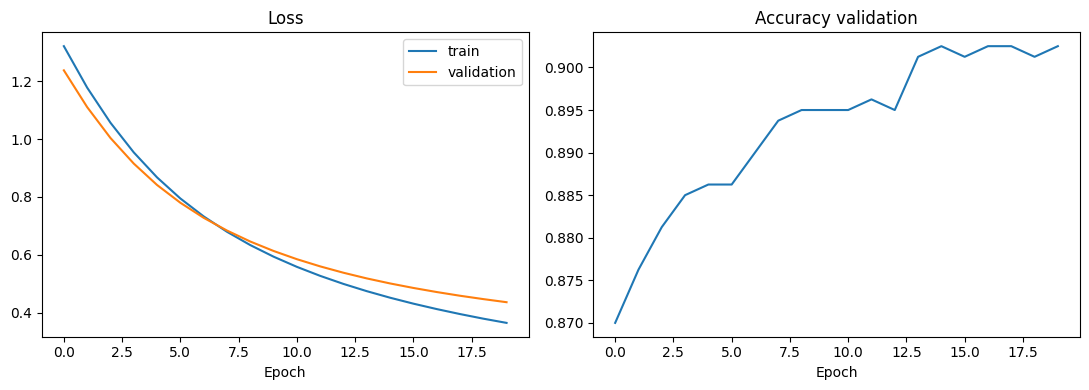

In [27]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(SEED)

def entrainer(model, epochs=20, lr=1e-3, batch_size=64):
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    criterion = nn.CrossEntropyLoss()            # logits bruts, labels long, pas de softmax
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_train))

        model.eval()
        with torch.no_grad():
            logits = model(X_val)
            hist["val_loss"].append(criterion(logits, y_val).item())
            hist["val_acc"].append((logits.argmax(1) == y_val).float().mean().item())
    return hist

baseline = nn.Linear(X_train.shape[1], len(CLASSES))   # une seule couche = régression logistique
hist = entrainer(baseline)

# Courbes : train et validation (pour repérer l'overfitting, cours 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["val_acc"]); ax[1].set_title("Accuracy validation"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

In [28]:
baseline.eval()
with torch.no_grad():
    pred = baseline(X_test).argmax(1)

res = classification_report(y_test.numpy(), pred.numpy())
print(f"Accuracy : {res['accuracy']:.3f}")
print(f"F1 macro : {res['f1_macro']:.3f}")
print("Matrice de confusion (lignes = vrai dialecte, colonnes = prédiction) :", CLASSES)
print(res["confusion"])

Accuracy : 0.894
F1 macro : 0.895
Matrice de confusion (lignes = vrai dialecte, colonnes = prédiction) : ['DZ', 'MA', 'TN', 'MSA']
[[177   6   7   8]
 [ 17 172   5   4]
 [  9   6 180   3]
 [ 14   2   3 179]]


In [12]:
torch.manual_seed(SEED)
baseline = nn.Linear(X_train.shape[1], len(CLASSES))
hist = entrainer(baseline, epochs=60)
print("Accuracy validation finale :", round(hist["val_acc"][-1], 3))

Accuracy validation finale : 0.905


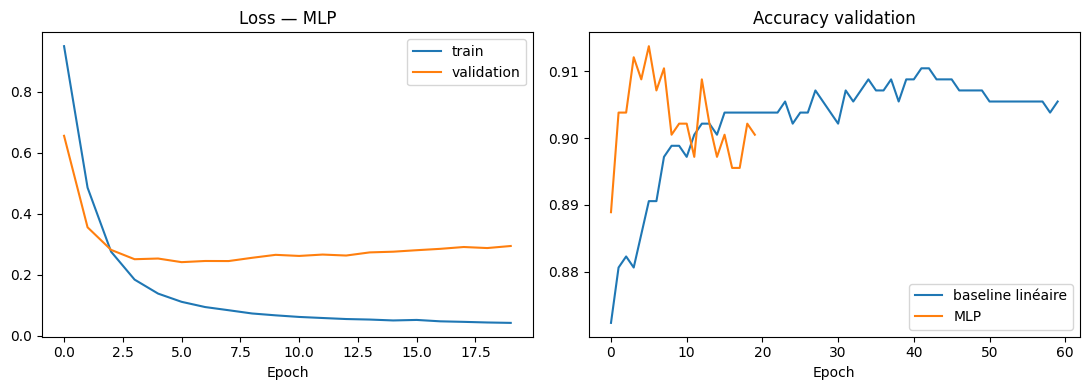

Accuracy validation finale — MLP : 0.9


In [13]:
torch.manual_seed(SEED)

mlp = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, len(CLASSES)),    # logits bruts, toujours pas de softmax
)
hist_mlp = entrainer(mlp, epochs=20)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_mlp["train_loss"], label="train"); ax[0].plot(hist_mlp["val_loss"], label="validation")
ax[0].set_title("Loss — MLP"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["val_acc"], label="baseline linéaire"); ax[1].plot(hist_mlp["val_acc"], label="MLP")
ax[1].set_title("Accuracy validation"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Accuracy validation finale — MLP :", round(hist_mlp["val_acc"][-1], 3))

In [29]:
import copy

def entrainer_v2(model, epochs=20, lr=1e-3, batch_size=64, weight_decay=0.0):
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    meilleur_acc, meilleurs_poids, meilleure_epoch = -1, None, -1

    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_train))

        model.eval()
        with torch.no_grad():
            logits = model(X_val)
            acc = (logits.argmax(1) == y_val).float().mean().item()
            hist["val_loss"].append(criterion(logits, y_val).item())
            hist["val_acc"].append(acc)
        if acc > meilleur_acc:                       # early stopping : on retient la meilleure epoch
            meilleur_acc, meilleure_epoch = acc, epoch
            meilleurs_poids = copy.deepcopy(model.state_dict())

    model.load_state_dict(meilleurs_poids)           # on repart des meilleurs poids
    print(f"Meilleure epoch : {meilleure_epoch}, accuracy validation : {meilleur_acc:.3f}")
    return hist

resultats = {}
for wd in [0.0, 0.01, 0.1]:
    torch.manual_seed(SEED)
    mlp = nn.Sequential(nn.Linear(X_train.shape[1], 128), nn.ReLU(), nn.Linear(128, len(CLASSES)))
    print(f"--- weight decay = {wd}")
    resultats[wd] = (mlp, entrainer_v2(mlp, weight_decay=wd))

--- weight decay = 0.0
Meilleure epoch : 7, accuracy validation : 0.902
--- weight decay = 0.01
Meilleure epoch : 7, accuracy validation : 0.902
--- weight decay = 0.1
Meilleure epoch : 7, accuracy validation : 0.902


In [30]:
mlp_final = resultats[0.0][0]          # le MLP sans weight decay, avec les poids de la meilleure epoch
mlp_final.eval()
with torch.no_grad():
    pred = mlp_final(X_test).argmax(1)

res = classification_report(y_test.numpy(), pred.numpy())
print(f"Accuracy : {res['accuracy']:.3f}")
print(f"F1 macro : {res['f1_macro']:.3f}")
print("Matrice de confusion :", CLASSES)
print(res["confusion"])

Accuracy : 0.886
F1 macro : 0.887
Matrice de confusion : ['DZ', 'MA', 'TN', 'MSA']
[[176   7   7   8]
 [ 20 169   6   3]
 [ 11   6 179   2]
 [ 14   1   5 178]]


In [16]:
import numpy as np

def score_test(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test).argmax(1)
    r = classification_report(y_test.numpy(), pred.numpy())
    return r["accuracy"], r["f1_macro"]

SEEDS = [42, 43, 44]
scores = {"baseline": [], "mlp": []}

for s in SEEDS:
    torch.manual_seed(s)
    base = nn.Linear(X_train.shape[1], len(CLASSES))
    entrainer(base, epochs=20)
    scores["baseline"].append(score_test(base))

    torch.manual_seed(s)
    mlp = nn.Sequential(nn.Linear(X_train.shape[1], 128), nn.ReLU(), nn.Linear(128, len(CLASSES)))
    entrainer_v2(mlp, epochs=20, weight_decay=0.0)
    scores["mlp"].append(score_test(mlp))

for nom, liste in scores.items():
    acc = np.array([a for a, f in liste]); f1 = np.array([f for a, f in liste])
    print(f"{nom:9s} accuracy {acc.mean():.3f} ± {acc.std():.3f} | F1 macro {f1.mean():.3f} ± {f1.std():.3f} | par seed : {np.round(acc, 3)}")

Meilleure epoch : 5, accuracy validation : 0.914
Meilleure epoch : 3, accuracy validation : 0.914
Meilleure epoch : 3, accuracy validation : 0.915
baseline  accuracy 0.890 ± 0.001 | F1 macro 0.891 ± 0.001 | par seed : [0.891 0.889 0.891]
mlp       accuracy 0.899 ± 0.003 | F1 macro 0.900 ± 0.003 | par seed : [0.896 0.9   0.902]


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
import pandas as pd
DATA = "/content/drive/MyDrive/darija_project/data"

uni = pd.read_parquet(f"{DATA}/interim/unified_v0.parquet")
print(uni.shape)
print(uni.columns.tolist())
print(pd.crosstab(uni["dataset"], uni["dialect"]))

(2571555, 14)
['id', 'text', 'dialect', 'script', 'task', 'label', 'label_orig', 'dataset', 'sub_source', 'orig_split', 'group_id', 'usage', 'n_chars', 'n_words']
dialect              DZ    EN    FR       MA   MSA     TN
dataset                                                  
algerian_dialect  45000     0     0        0     0      0
atlaset               0     0     0  1174196     0      0
darijabridge          0     0     0  1235091     0      0
fassila           20158     0     0        0     0      0
flores_plus           0  2009  2009     2009  2009   2009
tsac                  0     0     0        0     0  17065
tunizi                0     0     0        0     0  70000
